# HW#6: Numerical Gradient

In this assignment we will be implementing the TwoLayerNet class by creating our own networks to classify Iris flowers, and the MNIST network that we saw in the last assignment. We will need to train and test these networks to understand the full process of how to create our own neural networks.

## TwoLayerNet Class:
Before we can start implementing we first need to create our two layer neural network class. We will implement the one we created with the professor in lecture. First we need to import our necessary libraries such as NumPy, matplotlib, pandas, and pickle. Next we can start creating our network. Our initialization of the network will be two layers this we need to sets of weights and biases. For the class we need ot input the input size for our network the hidden layer size an dhte output size for our neural network. From there we will use the sigmoid active function and softmax. Next we will write our predict function which does the actual prediction of our neural network. Then we will finally do the cross entropy error, loss evaluation, and numerical gradient:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import pickle



In [2]:
class TwoLayerNet:
    def __init__(self, input_size, hidden_size, output_size, weight_init_std=0.01):
        self.params = {}
        self.params["w1"] = weight_init_std * np.random.randn(input_size, hidden_size)
        self.params["b1"] = np.zeros(hidden_size)
        self.params["w2"] = weight_init_std * np.random.randn(hidden_size, output_size)
        self.params["b2"] = np.zeros(output_size)
    
    def sigmoid(self,s):
        return 1/(1 + np.exp(-s))
    
    def softmax(self,s):
        if s.ndim ==1:
            s = s-np.max(s)
            exp_s = np.exp(s)
            return exp_s / np.sum(exp_s)
        else:
            s = s-np.max(s, axis = 1, keepdims = True)
            exp_s = np.exp(s)
            return exp_s / np.sum(exp_s, axis = 1, keepdims = True)

    def predict(self,x):
        w1 , w2 = self.params["w1"], self.params["w2"]
        b1 , b2 = self.params["b1"], self.params["b2"]
        a1 = x@w1 + b1
        z1 = self.sigmoid(a1)
        a2 = z1@w2 + b2
        yhat = self.softmax(a2)
        return yhat

    def cross_entropy_error(self, y, yhat):
        if y.ndim == 1:
            y = y.reshape((1, y.size))
            yhat = yhat.reshape((1, yhat.size))
        batch_size = y.shape[0]
        # print(batch_size)
        return -np.sum(y*np.log(yhat + 1e-7))/batch_size

    def loss(self, x, y):
        yhat = self.predict(x)
        return self.cross_entropy_error(y, yhat)

    # numerical gradient
    def numerical_gradient(self, x, y):
        h= 1e-4
        grad = {}
        # loop through every weight
        for k in self.params.keys():
            grad[k] = np.zeros_like(self.params[k])
            iter = np.nditer(self.params[k], flags= ["multi_index"], op_flags= ["readwrite"])

            while not iter.finished:
                idx = iter.multi_index
                tmp = self.params[k][idx]
                self.params[k][idx] = tmp + h
                # f(x+h)
                fh1 = self.loss(x, y)
                self.params[k][idx] = tmp - h
                #f(x-h)
                fh2 = self.loss(x, y)
                # Numerical gradient
                grad[k][idx] = (fh1-fh2)/(2*h)
                # Restore value
                self.params[k][idx] = tmp
                iter.iternext()
        return grad 


        

## Part 1: Iris Nerual Network Design, Testing and Training

Lets start off with the Iris neural network. Based off our data set we will need 4 inouts for the sepal length, sepal width, petal length, and petal width. and since there are 3 classes of flowers there will be 3 outputs. I decided to set the hidden layer size as 10 just as we did in the lecture. 

In [3]:
net = TwoLayerNet(input_size = 4, hidden_size = 10, output_size = 3)

For our training dataset we will use a predefined data set given by the professor from a GitHub repository. We wil need to set the 4 inputs that will be used as inputs for the network which are sepal.length, sepal.width, petal.length, petal.width. then we need ot set the ouptut as the variety which is in the data set. What were doing is were converting each of the flower three flower catogries into one-hot encoded integer. Next we convert the pandas dataset into NumPy arrays so that we can use sets for our network. Next we need ot split the data for training and testing. During the lecture we decided to use 80% of the dataset for training and the other 20% for testing so thats what I decided to use for our network. Next we split that data into two subsets of data x/y train and x/y test. we can see the shape of them we have 120 samples for training and 30 samples for testing where x is the input and y is the output. (I had to rename the split data arrays becaus it was interfering with the the split data arrays of the MNIST neural network) 

In [56]:
df = pd.read_csv('iris.csv')

# Input features
X = df[['sepal.length', 'sepal.width',
        'petal.length', 'petal.width']]

# One-hot encoded output
y = pd.get_dummies(df['variety'], dtype=int)

# Convert to NumPy arrays
X = X.to_numpy()
y = y.to_numpy()

# Shuffle indices
np.random.seed(42)
indices = np.random.permutation(len(X))

# 80% training
train_size = int(0.8 * len(X))

train_indices = indices[:train_size]
test_indices = indices[train_size:]

# Split data
X_train_iris = X[train_indices]
X_test_iris = X[test_indices]
y_train_iris = y[train_indices]
y_test_iris = y[test_indices]

print(X_train_iris.shape)
print(X_test_iris.shape)
print(y_train_iris.shape)
print(y_test_iris.shape)

(120, 4)
(30, 4)
(120, 3)
(30, 3)


Next we need ot set our training parameters. We will do 10000 training iterations, set the train size to be 120 samples, batch size will be 64 which means that 64 random trained samples will be selected between iterations. The learning_rate will control how much the weights and biases are adjusted during training. The train_loss is an empty list that stores the loss calculated from the class function during each iteration. Next we will train the model where we wil loop our 10000 iterations. There we will randomly select 64 indicies from the training set. Here the x batch will contain the inputs and y batch the ouptus. After we calculate the numerical gradient using these batches, we will update the networks paramaters weights and baises and calculate the loss.

In [57]:
iters_num = 10000
train_size = X_train_iris.shape[0]
batch_size = 64
learning_rate = 0.01

train_loss = []


for i in range(iters_num):

    batch_mask = np.random.choice(train_size, batch_size)

    X_batch_iris = X_train_iris[batch_mask]
    y_batch_iris = y_train_iris[batch_mask]

    grad = net.numerical_gradient(X_batch_iris, y_batch_iris)

    for key in net.params.keys():
        net.params[key] -= learning_rate * grad[key]

    loss = net.loss(X_batch_iris, y_batch_iris)
    train_loss.append(loss)

Next we can visualize the traiing loss and as we can see that at less iterations we have more loss and when we increase the iterations we can decrease that loss substantually. However one thing I noticed is that when increasing the number of interations in the training parameters, it takes a lot longer to train the network and due to limited computing power I set it as 10000. However if we keep increasing the iterations the loss will keep going down. 

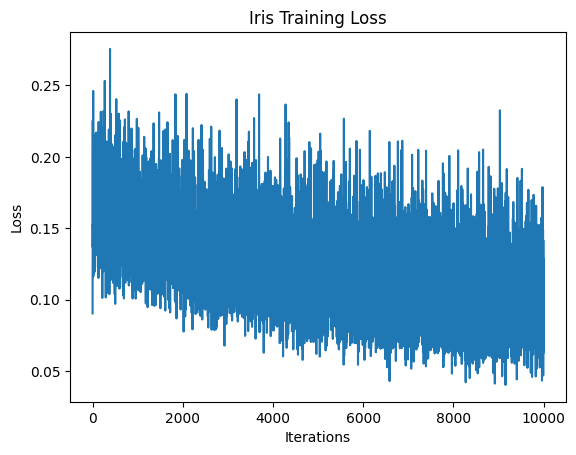

In [61]:
plt.plot(train_loss)
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.title("Iris Training Loss")
plt.show()

Next we can begin testing our neural network we created. First we need to create the pkl file for our network:

In [ ]:
with open("Hadzic_iris_nn_model.pkl", "wb") as f:
    pickle.dump(net, f)

After creating our model we can start testing it. First we load the model into the code and create a  As mentioned before we will use the testing dataset where we seperated 20 percent of the orginal set for testing. Here we will show if the prediction is correct. We are using 30 samples as mentioned before. 

In [73]:
with open("Hadzic_iris_nn_model.pkl", "rb") as f:
    loaded_net = pickle.load(f)

class_names = pd.get_dummies(df['variety'], dtype=int).columns.to_list()

for i in range(len(X_test_iris)):

    yhat = loaded_net.predict(X_test_iris[i])

    actual = np.argmax(y_test_iris[i])
    predicted = np.argmax(yhat)

    if actual == predicted:
        correct = True
    else:
        correct = False

    print("Actual Class:", class_names[actual])
    print("Predicted Class:", class_names[predicted])
    print("Correct:", correct)
    print("-----------------------")

Actual Class: Versicolor
Predicted Class: Versicolor
Correct: True
-----------------------
Actual Class: Setosa
Predicted Class: Setosa
Correct: True
-----------------------
Actual Class: Versicolor
Predicted Class: Versicolor
Correct: True
-----------------------
Actual Class: Versicolor
Predicted Class: Versicolor
Correct: True
-----------------------
Actual Class: Setosa
Predicted Class: Setosa
Correct: True
-----------------------
Actual Class: Versicolor
Predicted Class: Versicolor
Correct: True
-----------------------
Actual Class: Virginica
Predicted Class: Virginica
Correct: True
-----------------------
Actual Class: Virginica
Predicted Class: Virginica
Correct: True
-----------------------
Actual Class: Setosa
Predicted Class: Setosa
Correct: True
-----------------------
Actual Class: Versicolor
Predicted Class: Versicolor
Correct: True
-----------------------
Actual Class: Virginica
Predicted Class: Virginica
Correct: True
-----------------------
Actual Class: Virginica
Predi

We can see that it is extremly accurate and that it guessed each sample correctly. Its really accurate because of how many iterations I used (10000). We were able to use 10000 iterations because there were only 3 inputs so training took a lot less time. However in the MNIST network we will see that a lot of inputs will cause the training time to significatnly increase.

## Part 2: MNIST Nerual Network Design, Testing and Training

Lets move onto the MNIST neural network. Based off our data set we will need 784 inouts for each pixel value of the 28x28 picture and since there are 10 digits there will be 10 output size. I decided to set the hidden layer size as 100 just as we did in the lecture.

In [9]:
import gzip
import numpy as np

In [10]:
mnistnet = TwoLayerNet(input_size=28*28, hidden_size=100, output_size=10)

Next we create a function to load the data set. Since the data set is in a zip which was provided by the professor we will use gzip just like in the lecture. Hwere we will unzi and open the files. We have 4 files 2 files are the images and labels for the training and 2 are images and labels for testing. We resize the images and size of the datasets and we split it into X_train, X_test, y_train, and y_test NumPy arrays. The train arrays have 60 thousand samples and the test arrays have 10 thousand samples.

In [11]:
def load_mnist():
    key_file = {
        "train_img": "train-images-idx3-ubyte.gz",
        "train_label": "train-labels-idx1-ubyte.gz",
        "test_img": "t10k-images-idx3-ubyte.gz",
        "test_label": "t10k-labels-idx1-ubyte.gz"
    }

    with gzip.open(key_file["train_img"], "rb") as f:
        X_train = np.frombuffer(f.read(), dtype=np.uint8, offset=16).reshape(-1, 28*28)

    with gzip.open(key_file["train_label"], "rb") as f:
        labels = np.frombuffer(f.read(), dtype=np.uint8, offset=8).reshape(-1, 1)
    y_train = np.eye(10)[labels].reshape(-1, 10)

    with gzip.open(key_file["test_img"], "rb") as f:
        X_test = np.frombuffer(f.read(), dtype=np.uint8, offset=16).reshape(-1, 28*28)

    with gzip.open(key_file["test_label"], "rb") as f:
        labels = np.frombuffer(f.read(), dtype=np.uint8, offset=8).reshape(-1, 1)
    y_test = np.eye(10)[labels].reshape(-1, 10)

    return X_train, y_train, X_test, y_test


In [12]:
X_train, y_train, X_test, y_test = load_mnist()
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(60000, 784)
(60000, 10)
(10000, 784)
(10000, 10)


Next lets train our model. We first need to set the training parameters just like how we did in the Iris training set. I set the number of iterations to only 6 because of how many parameters there in this model it will take extremly long to train the model with my given computer. There are 784 inputs and with a sample size of 60 thousand, training 10000 iterations like the Iris model will take an extremly long time. Next we set the train size to be 60 thousand samples to reflect our training image data set size, batch size will be 64 which means that 64 random trained samples will be selected between iterations. The learning_rate will control how much the weights and biases are adjusted during training. Next we will train the model where we wil loop our 6 iterations. There we will randomly select 64 indicies from the training set. Here the x batch will contain the inputs (training images) and y batch the ouptus (training labels). After we calculate the numerical gradient using these batches, we will update the networks paramaters weights and baises and calculate the loss.

In [51]:
iters_num = 6
training_size = X_train.shape[0]
batch_size = 64
learning_rate = 0.01

for i in range(iters_num):
    batch_mask = np.random.choice(training_size, batch_size)
    X_batch = X_train[batch_mask]
    y_batch = y_train[batch_mask]

    grad = mnistnet.numerical_gradient(X_batch, y_batch)

    for key in net.params.keys():
        mnistnet.params[key] -= learning_rate * grad[key]

After training our model we need to turn it into a pkl file so that we can implement it for testing:

In [65]:
import pickle

with open("Hadzic_mnist_nn_model.pkl", "wb") as f:
    pickle.dump(mnistnet, f)

After creating the pkl file we can implement it and test the neural network. First we load the pklfile and create a net. From there we will use our testing data (test images and labels) to test the network. Since there is a lot of test images (10000) we will only use 100 images to test. 

In [32]:
with open("Hadzic_mnist_nn_model.pkl", "rb") as f:
    loaded_mnistnet = pickle.load(f)

In [72]:
for i in range(100):
    yhat = loaded_mnistnet.predict(X_test[i])

    actual = np.argmax(y_test[i])
    predicted = np.argmax(yhat)

    print("Actual:", actual)
    print("Predicted:", predicted)
    if actual == predicted:
        print("Correct: True")
    else:
        print("Correct: False")
    print("-------------------------------")

Actual: 7
Predicted: 7
Correct: True
-------------------------------
Actual: 2
Predicted: 1
Correct: False
-------------------------------
Actual: 1
Predicted: 1
Correct: True
-------------------------------
Actual: 0
Predicted: 7
Correct: False
-------------------------------
Actual: 4
Predicted: 3
Correct: False
-------------------------------
Actual: 1
Predicted: 1
Correct: True
-------------------------------
Actual: 4
Predicted: 3
Correct: False
-------------------------------
Actual: 9
Predicted: 7
Correct: False
-------------------------------
Actual: 5
Predicted: 3
Correct: False
-------------------------------
Actual: 9
Predicted: 7
Correct: False
-------------------------------
Actual: 0
Predicted: 0
Correct: True
-------------------------------
Actual: 6
Predicted: 7
Correct: False
-------------------------------
Actual: 9
Predicted: 7
Correct: False
-------------------------------
Actual: 0
Predicted: 7
Correct: False
-------------------------------
Actual: 1
Predicted: 1
C

If we take a look at the results of testing we can see that the model failed to predicted a lot of the samples and that is entirely because of the the way we trained it and how we setup the training parameters. Since we only did 6 iterations, there was not enough training done to achive high reliability and thats due to computing power. Due to my device and many of our everyday computers low computing power for training models, it would have taken a very long time to achive a high reliability and a low loss. Thats why we see these computer chips that are designed to train these huge parameters. 

## Conclusion

In conclusion I learned a lot from this homework. From learning to import a dataset for my network to training and testing the network, this information is very helpful for my project for this class. It shows the fundementals of how these modern AI models are designed and gives me a better understanding of Pattern Recognition, Neural Network Design, and AI.